# HAR70+ exploratory data analysis — topic approval starter

**Goal:** establish *actual* class balance, participant variability, sensor-signal quality and feasible labels **before choosing the experiment**. Source: [UCI HAR70+](https://archive.ics.uci.edu/dataset/780/har70), DOI [10.24432/C5CW3D](https://doi.org/10.24432/C5CW3D). Paper: [Ustad et al. (2023)](https://doi.org/10.3390/s23052368).

**Dataset:** 18 older participants, 50 Hz, two 3-axis accelerometers (back/thigh), 7 activity labels. This is **activity recognition, not fall detection**. One CSV per participant. Participant identity here is the *file name*, not a biological/demographic record.

1. Download `har70.zip` from UCI and unzip. Put the participant CSVs under `data/har70plus/` (nested folders are fine).
2. From the notebook directory install: `python3 -m pip install pandas numpy matplotlib seaborn jupyter`.
3. Run all cells. Result images are written to `outputs/`.

These notebook visualizations are computed from **your downloaded data**, unlike the separate published-data overview PNG.

In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_data_dir():
    roots = [Path.cwd(), *Path.cwd().parents, Path.home(), Path.home() / "Downloads", Path.home() / "Documents", Path("/")]
    seen = set()
    for root in roots:
        if not root.exists():
            continue
        for candidate in [root / "data" / "har70plus", root / "har70plus", root]:
            norm = candidate.resolve()
            if norm in seen:
                continue
            seen.add(norm)
            if candidate.exists():
                csvs = sorted(candidate.rglob("*.csv"))
                if csvs:
                    return candidate, csvs
        for match in sorted(root.glob("**/har70plus"), key=lambda p: len(p.parts)):
            if match.is_dir():
                csvs = sorted(match.rglob("*.csv"))
                if csvs:
                    return match, csvs
    return Path("."), []

DATA_DIR, detected_files = find_data_dir()
files = detected_files or sorted(DATA_DIR.rglob("*.csv"))
OUT = Path("outputs")
OUT.mkdir(exist_ok=True, parents=True)
HZ = 50
CHANNELS = ["back_x", "back_y", "back_z", "thigh_x", "thigh_y", "thigh_z"]
ACTIVITY = {1:"Walking", 3:"Shuffling", 4:"Stairs up", 5:"Stairs down", 6:"Standing", 7:"Sitting", 8:"Lying"}
if not files:
    raise FileNotFoundError(f"No CSV files under {DATA_DIR.resolve()}. Download and extract HAR70+ first.")
print(f"Found {len(files)} participant CSVs (expected: 18)")
print([f.name for f in files])

Found 18 participant CSVs (expected: 18)
['501.csv', '502.csv', '503.csv', '504.csv', '505.csv', '506.csv', '507.csv', '508.csv', '509.csv', '510.csv', '511.csv', '512.csv', '513.csv', '514.csv', '515.csv', '516.csv', '517.csv', '518.csv']


## 1. Read the original participant recordings

Use `float32` for accelerations to reduce memory usage. **Do not drop** participants or uncommon activities before the dataset audit. Preserve timestamps so gaps can be detected.

In [11]:
frames = []
required = set(CHANNELS + ["timestamp", "label"])
for path in files:
    part = pd.read_csv(path)
    missing = required - set(part.columns)
    if missing:
        raise ValueError(f"{path}: missing columns {missing}")
    part = part[["timestamp", *CHANNELS, "label"]].copy()
    for col in CHANNELS:
        part[col] = pd.to_numeric(part[col], errors="coerce").astype("float32")
    part["label"] = pd.to_numeric(part["label"], errors="coerce")
    part["timestamp"] = pd.to_datetime(part["timestamp"], errors="coerce")
    part["participant"] = path.stem
    frames.append(part)

df = pd.concat(frames, ignore_index=True)
df["activity"] = df["label"].map(ACTIVITY)
print(f"Rows: {len(df):,} (UCI listed: 2,259,597)")
print(f"Participants: {df.participant.nunique()}")
print(df.head())

Rows: 2,259,597 (UCI listed: 2,259,597)
Participants: 18
                timestamp    back_x    back_y    back_z   thigh_x   thigh_y  \
0 2021-03-24 14:42:03.839 -0.999023 -0.063477  0.140625 -0.980469 -0.112061   
1 2021-03-24 14:42:03.859 -0.980225 -0.079346  0.140625 -0.961182 -0.121582   
2 2021-03-24 14:42:03.880 -0.950195 -0.076416  0.140625 -0.949463 -0.080566   
3 2021-03-24 14:42:03.900 -0.954834 -0.059082  0.140381 -0.957520 -0.046143   
4 2021-03-24 14:42:03.920 -0.972412 -0.042969  0.142822 -0.977051 -0.023682   

    thigh_z  label participant  activity  
0 -0.048096      6         501  Standing  
1 -0.051758      6         501  Standing  
2 -0.067139      6         501  Standing  
3 -0.050781      6         501  Standing  
4 -0.026611      6         501  Standing  


## 2. Label distribution (the first essential presentation figure)

Samples at 50 Hz are *not independent*. The graph describes recorded time, not the number of independent examples or the prevalence of activities in everyday care.

         label  samples  minutes  percent
1      Walking  1079312   359.77    47.77
3    Shuffling    66058    22.02     2.92
4    Stairs up     4560     1.52     0.20
5  Stairs down     4978     1.66     0.22
6     Standing   418055   139.35    18.50
7      Sitting   483452   161.15    21.40
8        Lying   203182    67.73     8.99


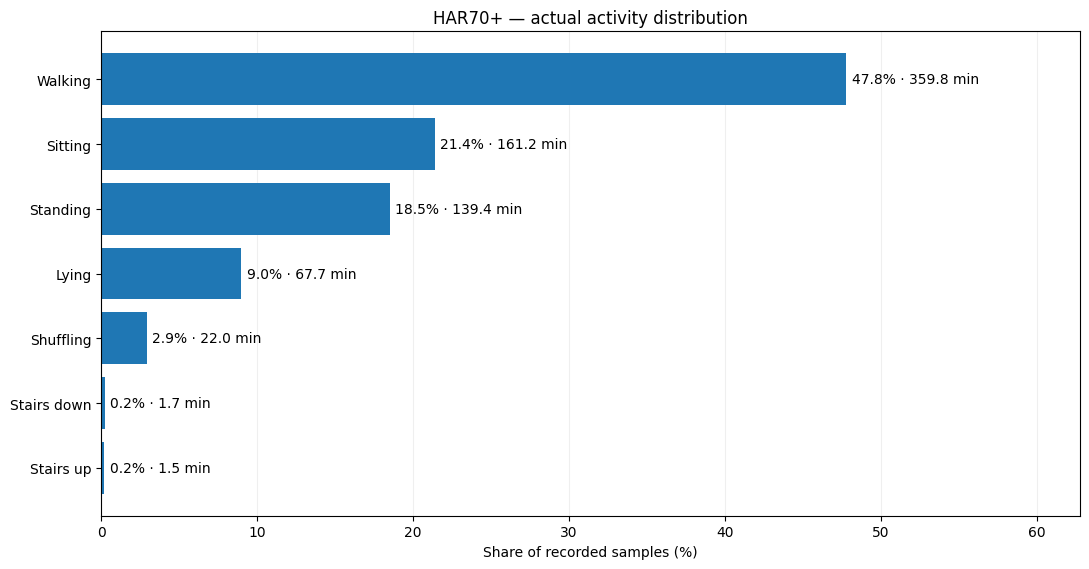

In [12]:
counts = df["label"].value_counts().reindex(ACTIVITY.keys(), fill_value=0)
summary = pd.DataFrame({
    "label": list(ACTIVITY.values()),
    "samples": counts.to_numpy(),
    "minutes": counts.to_numpy() / HZ / 60,
    "percent": 100 * counts.to_numpy() / len(df),
}, index=list(ACTIVITY.keys()))
print(summary.round(2).to_string())

shown = summary.sort_values("samples")
fig, ax = plt.subplots(figsize=(11, 5.8))
ax.barh(shown["label"], shown["percent"])
for i,(_,r) in enumerate(shown.iterrows()):
    ax.text(r["percent"]+.35, i, f'{r["percent"]:.1f}% · {r["minutes"]:.1f} min', va="center")
ax.set_xlim(0,max(60,shown["percent"].max()+15))
ax.set_xlabel("Share of recorded samples (%)")
ax.set_title("HAR70+ — actual activity distribution")
ax.grid(axis="x",alpha=.2);ax.set_axisbelow(True)
fig.tight_layout();fig.savefig(OUT/"01_actual_label_distribution.png",dpi=180);plt.show()

## 3. Participant representation — do all people contribute equally?

Plot minutes of each label **by participant**. This identifies missing classes in certain participants, which can break grouped train/test evaluations.

count    18.00
mean     41.84
std       5.77
min      29.00
25%      39.84
50%      41.05
75%      45.52
max      51.17
dtype: float64


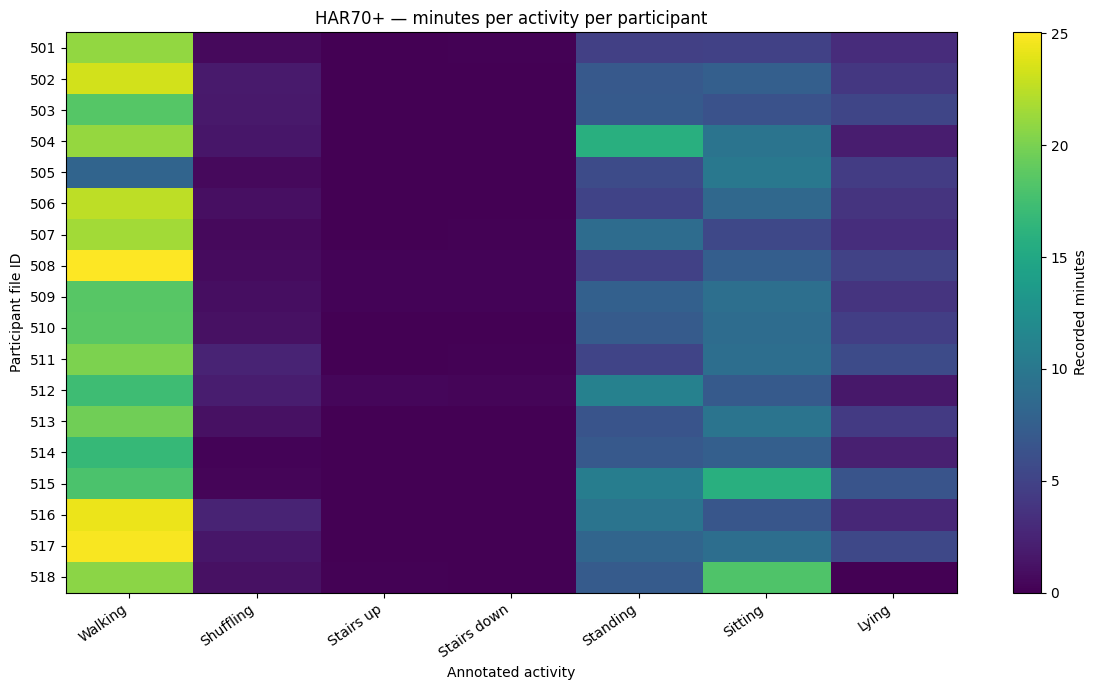

In [13]:
per_subject = pd.crosstab(df["participant"],df["activity"]).reindex(columns=list(ACTIVITY.values()), fill_value=0) / HZ / 60
print((per_subject.sum(axis=1)).describe().round(2))
fig,ax=plt.subplots(figsize=(12,7))
im=ax.imshow(per_subject.to_numpy(),aspect="auto")
ax.set_xticks(np.arange(len(per_subject.columns)),per_subject.columns,rotation=35,ha="right")
ax.set_yticks(np.arange(len(per_subject.index)),per_subject.index)
ax.set_xlabel("Annotated activity");ax.set_ylabel("Participant file ID")
ax.set_title("HAR70+ — minutes per activity per participant")
fig.colorbar(im,ax=ax,label="Recorded minutes")
fig.tight_layout();fig.savefig(OUT/"02_participant_activity_heatmap.png",dpi=180);plt.show()

## 4. Visualize real motion signals

Display a continuous few-second excerpt of *one activity*, showing how x/y/z accelerations vary at the back and thigh. Do not plot all 2.26M samples at once.

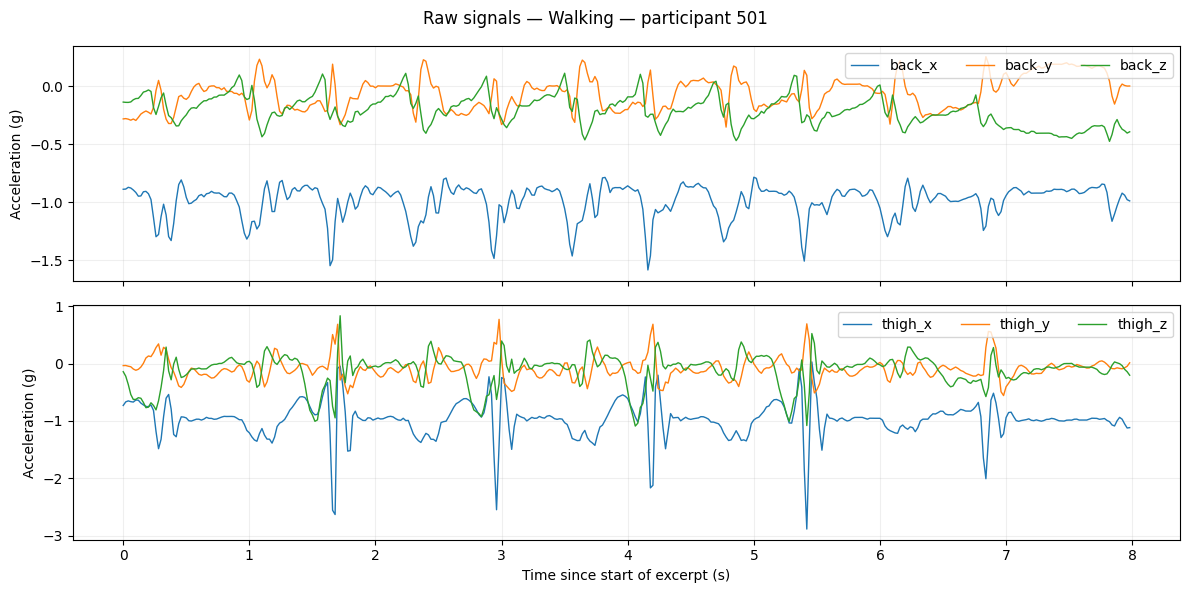

In [14]:
# Pick any label; change to 3 for shuffling, 7 for sitting, etc.
EXAMPLE_LABEL = 1
EXCERPT_SECONDS = 8
n = int(EXCERPT_SECONDS*HZ)
selected = None
for pid,part in df.groupby("participant",sort=False):
    v = part["label"].to_numpy()
    hits = np.flatnonzero(v == EXAMPLE_LABEL)
    for idx in hits[::max(1,n//2)]:
        if idx+n<=len(part) and np.all(v[idx:idx+n] == EXAMPLE_LABEL):
            selected = part.iloc[idx:idx+n]
            chosen_pid = pid
            break
    if selected is not None: break

if selected is None:
    print("No continuous excerpt found. Try a shorter EXCERPT_SECONDS or different EXAMPLE_LABEL.")
else:
    t = np.arange(len(selected))/HZ
    fig,axes=plt.subplots(2,1,figsize=(12,6),sharex=True)
    for a,sensor in zip(axes,["back", "thigh"]):
        for axis in ["x","y","z"]:
            a.plot(t,selected[f"{sensor}_{axis}"],label=f"{sensor}_{axis}",linewidth=1)
        a.set_ylabel("Acceleration (g)");a.legend(loc="upper right",ncol=3);a.grid(alpha=.2)
    axes[-1].set_xlabel("Time since start of excerpt (s)")
    fig.suptitle(f"Raw signals — {ACTIVITY[EXAMPLE_LABEL]} — participant {chosen_pid}")
    fig.tight_layout();fig.savefig(OUT/"03_real_acceleration_excerpt.png",dpi=180);plt.show()

## 5. Completeness, time gaps, and sensor sanity

The UCI dataset states there are no missing values; verify this in the downloaded files. A separate timestamp continuity check is also necessary.

In [15]:
print("Missing entries:")
print(df[["timestamp",*CHANNELS,"label"]].isna().sum())
print("Unexpected labels:",sorted(set(df.label.dropna().astype(int)) - set(ACTIVITY)))
print("Sensor value summary (g):")
print(df[CHANNELS].agg(["min","max","mean","std"]).round(3))

check=[]
for pid,part in df.groupby("participant",sort=False):
    dt=part["timestamp"].diff().dt.total_seconds().dropna()
    check.append({"participant":pid,"rows":len(part),
        "duration_min_at_50Hz":len(part)/HZ/60,
        "non_positive_steps":int((dt<=0).sum()),
        "gaps_gt_0_1_sec":int((dt>0.1).sum()),
        "timestamp_parse_failures":int(part.timestamp.isna().sum())})
qc=pd.DataFrame(check)
print(qc.to_string(index=False))
qc.to_csv(OUT/"participant_quality_audit.csv",index=False)

Missing entries:
timestamp    0
back_x       0
back_y       0
back_z       0
thigh_x      0
thigh_y      0
thigh_z      0
label        0
dtype: int64
Unexpected labels: []
Sensor value summary (g):
      back_x  back_y  back_z  thigh_x  thigh_y  thigh_z
min   -4.333  -2.031  -2.205   -7.942   -5.143   -7.594
max    0.363   1.577   1.179    3.395    5.725    3.953
mean  -0.870  -0.033   0.023   -0.680    0.003   -0.384
std    0.269   0.151   0.433    0.552    0.274    0.513
participant   rows  duration_min_at_50Hz  non_positive_steps  gaps_gt_0_1_sec  timestamp_parse_failures
        501 103860             34.620000                   0               10                         0
        502 131367             43.789000                   0               12                         0
        503 116413             38.804333                   0               14                         0
        504 150758             50.252667                   0               16                         0
  

## 6. How many valid 5-second learning windows?

Each window contains 250 samples at 50 Hz. Here we use **non-overlapping windows for exploration** and record their majority-label purity. In the actual experiment, split participant IDs into train/validation/test **before** creating possibly overlapping windows or normalizing data.

At 50 Hz, 1,000 raw rows represent just 20 seconds, **not 1,000 independent training examples**.

Non-overlap windows: 9032
Windows with >=90% same label: 82.5 %
purity          False  True 
majority_label              
Walking           627   3746
Shuffling         114     41
Stairs up          10      6
Stairs down        18      5
Standing          725    984
Sitting            70   1872
Lying              20    794


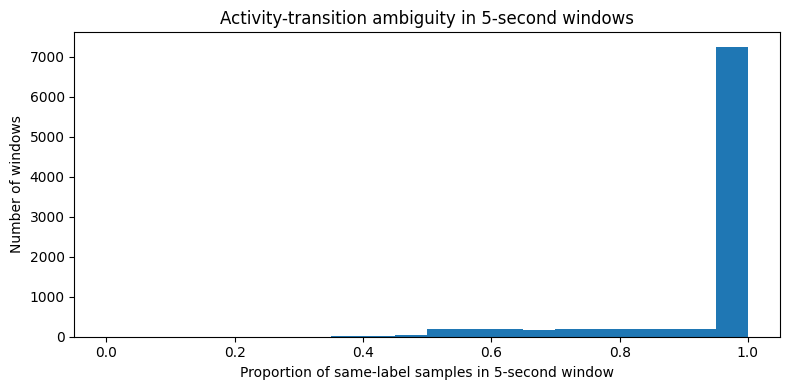

In [16]:
WINDOW=5*HZ
window_rows=[]
for pid,part in df.groupby("participant",sort=False):
    x=part["label"].to_numpy()
    nwin=len(x)//WINDOW
    if not nwin: continue
    a=x[:nwin*WINDOW].reshape(nwin,WINDOW)
    for w in a:
        vals,cnt=np.unique(w,return_counts=True)
        j=int(np.argmax(cnt))
        window_rows.append((pid,int(vals[j]),cnt[j]/WINDOW))
wdf=pd.DataFrame(window_rows,columns=["participant","majority_label","purity"])
print("Non-overlap windows:",len(wdf))
print("Windows with >=90% same label:",round(100*(wdf.purity>=.9).mean(),1),"%")
print(pd.crosstab(wdf.majority_label,wdf.purity>=.9).rename(index=ACTIVITY))
fig,ax=plt.subplots(figsize=(8,4))
ax.hist(wdf.purity,bins=np.linspace(0,1,21))
ax.set(xlabel="Proportion of same-label samples in 5-second window",ylabel="Number of windows",title="Activity-transition ambiguity in 5-second windows")
fig.tight_layout();fig.savefig(OUT/"04_window_purity.png",dpi=180);plt.show()

## 7. What to decide from this EDA

Record answers to these before model training:

- Are ascent/descent stairs numerous enough **across participants** for a seven-class test? If not, propose **five core classes** (walking, shuffling, standing, sitting, lying), and disclose that rare stair classes are outside primary scope.
- Which labels are confusing or transition-heavy? Use per-participant and window-purity charts to justify preprocessing.
- Is the sensor data complete? Document missing values and timestamp gaps. *Robustness experiments simulate controlled sensor loss; they do not imply that actual recordings were corrupted.*
- Does the question require HARTH? **Yes**, if you claim cross-age transfer. Download [HARTH UCI 779](https://archive.ics.uci.edu/dataset/779/harth) separately. Match sensor axes, 50 Hz, labels and preprocessing. **Do not** infer an individual's age or walking-aid status from the CSV filename.

**Provisional experiment:** train on HARTH adults, test zero-shot on held-out HAR70+ participants, and compare with fine-tuning on separate HAR70+ training participants. Use macro-F1, per-class recall, confusion matrix and predefined sensor-masking tests. Report participant-disjoint results and uncertainty. Not a fall detector.
